
# RQ28 — What should the final PhageLysClass architecture be?

## Scientific question

**Which deployment architecture best converts the completed benchmark into a coherent PhageLysClass product: `2 core`, `5 flat/co-equal models`, or `2 core + 3 auxiliary`?**

RQ28 is the architecture-freezing stage. It does **not** retrain models, tune thresholds, optimize ensemble weights, or reinterpret benchmark tasks as equivalent prediction targets.

It consumes the frozen evidence from:

- RQ11 — binary subtype recognition vs clean multiclass discrimination;
- RQ26 — defensible individual deployment candidates;
- RQ27 — ensemble gain, stabilization, and error complementarity.

The output of RQ28 is a **production recipe**, not final fitted production weights.

### The three architectures

**A. `2 core`**

1. global lytic recognition;
2. clean multiclass functional discrimination.

**B. `5 flat models`**

1. global lytic recognition;
2. clean multiclass;
3. endolysin binary;
4. depolymerase binary;
5. VAL binary;

all exposed as co-equal prediction modules.

**C. `2 core + 3 auxiliary`**

Core:

1. global lytic recognition;
2. clean multiclass functional discrimination.

Optional auxiliary compatibility scores:

3. endolysin binary;
4. depolymerase binary;
5. VAL binary.

The distinction between B and C is therefore **semantic and operational**, not merely the number of fitted estimators.



## Architecture contract

RQ28 uses **constraint satisfaction**, not an arbitrary scalar architecture score.

The final architecture must satisfy all of the following:

1. **Unambiguous primary flow** — the standard user path must have clear precedence.
2. **Broad global recognition** — the production global model should represent general lytic-vs-background recognition, not only an isolated benchmark stress-test background.
3. **Explicit functional resolution** — mutually exclusive clean subtype assignment belongs to the multiclass core.
4. **Preserve compatibility evidence** — binary subtype models capture a different biological question and should not be discarded if they add interpretable information.
5. **Support-aware VAL handling** — VAL cannot be promoted to an independent high-confidence core output without a guardrail.
6. **Respect formulation non-equivalence** — binary subtype positives mean *compatibility versus non-lytic background*; multiclass outputs mean *relative discrimination among clean lytic alternatives*.
7. **Minimal default path** — optional diagnostics should not make every standard inference unnecessarily complex.
8. **No unnecessary weighting** — RQ27 showed no material reason to prefer validation-weighted ensembles over simple soft voting.

The architecture that satisfies all mandatory constraints is frozen for RQ29.



## Production-model selection policy

RQ28 must also freeze the **recipe** used by each retained module.

Candidate recipes are:

- RQ26 individual strategies;
- RQ27 **unweighted** soft-voting ensembles.

Validation-weighted ensembles are not eligible for production because RQ27 found negligible practical benefit from weighting and unweighted averaging is simpler and less dependent on validation noise.

A production recipe must first remain within the already-established `0.02 MCC` mean-performance competitive band. Within that band, the selection is purpose-specific and lexicographic:

- **global core (`global_mixed`)**: worst-case MCC → strict `R30/S30` MCC → mean MCC → lower surface range → fewer members;
- **multiclass core**: strict `R30/S30` MCC → worst-case MCC → mean MCC → lower surface range → fewer members;
- **endolysin auxiliary**: mean MCC → worst-case MCC → strict MCC → fewer members;
- **depolymerase auxiliary**: strict MCC → mean MCC → worst-case MCC → fewer members;
- **VAL auxiliary**: **individual models only**, mean MCC → worst-case MCC → strict MCC.

The VAL single-model restriction is deliberate: RQ27 showed that its ensemble could improve average MCC while materially weakening the strict-regime advantage, and RQ11 established VAL as the evidence-limited subtype.


In [1]:

from pathlib import Path
import json
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 500)
pd.set_option("display.width", 300)
pd.set_option("display.max_rows", 500)

COMPETITIVE_GAP = 0.02

TASK_ORDER = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
    "multiclass_clean",
]

PRODUCTION_ENDPOINTS = [
    "global_mixed",
    "multiclass_clean",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
]

CORE_ENDPOINTS = ["global_mixed", "multiclass_clean"]
AUX_ENDPOINTS = [
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
]

SUBTYPE_TO_TASK = {
    "endolysin": "subtype_endolysin",
    "depolymerase": "subtype_depolymerase",
    "val": "subtype_val",
}

TASK_LABEL = {
    "global_easy": "Global easy",
    "global_hard": "Global hard",
    "global_mixed": "Global mixed",
    "subtype_endolysin": "Endolysin binary",
    "subtype_depolymerase": "Depolymerase binary",
    "subtype_val": "VAL binary",
    "multiclass_clean": "Clean multiclass",
}


def find_project_root(start=None):
    explicit = os.environ.get("PHAGELYSCLASS_ROOT")
    if explicit:
        root = Path(explicit).expanduser().resolve()
        if (
            (root / "results/analysis_supervised/stage12a/supervised_master_results.tsv").is_file()
            and (root / "results/analysis_deployment/rq26/rq26_topK_individual_candidates.tsv").is_file()
            and (root / "results/analysis_deployment/rq27/rq27_ensemble_vs_individual.tsv").is_file()
        ):
            return root
        raise FileNotFoundError(
            f"PHAGELYSCLASS_ROOT does not satisfy RQ28 contract: {root}"
        )

    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_supervised/stage12a/supervised_master_results.tsv").is_file()
            and (candidate / "results/analysis_deployment/rq26/rq26_topK_individual_candidates.tsv").is_file()
            and (candidate / "results/analysis_deployment/rq27/rq27_ensemble_vs_individual.tsv").is_file()
        ):
            return candidate

    raise FileNotFoundError(
        "Could not locate PhageLysClass root with Stage12A, RQ26, and RQ27 outputs."
    )


ROOT = find_project_root()

STAGE12A = ROOT / "results/analysis_supervised/stage12a"
SUP_CACHE = ROOT / "results/analysis_supervised/notebook_cache"
RQ26_DIR = ROOT / "results/analysis_deployment/rq26"
RQ27_DIR = ROOT / "results/analysis_deployment/rq27"

RQ28_OUT = ROOT / "results/analysis_deployment/rq28"
FIG_DIR = RQ28_OUT / "figures"
RQ28_OUT.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("RQ28_OUT:", RQ28_OUT)
print("No retraining, threshold tuning, or new ensemble search is performed.")


ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
RQ28_OUT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_deployment/rq28
No retraining, threshold tuning, or new ensemble search is performed.


## 1. Real-project preflight

In [2]:

PATHS = {
    "supervised_master": STAGE12A / "supervised_master_results.tsv",
    "rq11_regime": SUP_CACHE / "rq11_regime_table.tsv",
    "rq11_formulation_summary": SUP_CACHE / "rq11_formulation_summary.tsv",
    "rq26_topK": RQ26_DIR / "rq26_topK_individual_candidates.tsv",
    "rq26_manifest": RQ26_DIR / "rq26_manifest.json",
    "rq27_ensemble_vs_individual": RQ27_DIR / "rq27_ensemble_vs_individual.tsv",
    "rq27_task_answer": RQ27_DIR / "rq27_task_answer.tsv",
    "rq27_weighted_summary": RQ27_DIR / "rq27_weighted_vs_unweighted_summary.tsv",
    "rq27_task_complementarity": RQ27_DIR / "rq27_task_complementarity_summary.tsv",
    "rq27_manifest": RQ27_DIR / "rq27_manifest.json",
}

preflight = pd.DataFrame([
    {
        "artifact": name,
        "path": str(path),
        "exists": path.is_file(),
    }
    for name, path in PATHS.items()
])
display(preflight)

missing = preflight[~preflight["exists"]]
if len(missing):
    raise FileNotFoundError(
        "RQ28 requires completed RQ11, RQ26, and RQ27 artifacts:\n"
        + missing[["artifact", "path"]].to_string(index=False)
    )

print("REAL_PROJECT_PREFLIGHT_OK")


,artifact,path,exists
0,supervised_master,/home/david/Desktop/colabs/inta_project/phagel...,True
1,rq11_regime,/home/david/Desktop/colabs/inta_project/phagel...,True
2,rq11_formulation_summary,/home/david/Desktop/colabs/inta_project/phagel...,True
3,rq26_topK,/home/david/Desktop/colabs/inta_project/phagel...,True
4,rq26_manifest,/home/david/Desktop/colabs/inta_project/phagel...,True
5,rq27_ensemble_vs_individual,/home/david/Desktop/colabs/inta_project/phagel...,True
6,rq27_task_answer,/home/david/Desktop/colabs/inta_project/phagel...,True
7,rq27_weighted_summary,/home/david/Desktop/colabs/inta_project/phagel...,True
8,rq27_task_complementarity,/home/david/Desktop/colabs/inta_project/phagel...,True
9,rq27_manifest,/home/david/Desktop/colabs/inta_project/phagel...,True


REAL_PROJECT_PREFLIGHT_OK


## 2. Load and validate frozen evidence

In [3]:

master = pd.read_csv(PATHS["supervised_master"], sep="\t", low_memory=False)
rq11_regime = pd.read_csv(PATHS["rq11_regime"], sep="\t", low_memory=False)
rq11_summary = pd.read_csv(
    PATHS["rq11_formulation_summary"], sep="\t", low_memory=False
)
topk = pd.read_csv(PATHS["rq26_topK"], sep="\t", low_memory=False)
ensemble = pd.read_csv(
    PATHS["rq27_ensemble_vs_individual"], sep="\t", low_memory=False
)
rq27_task = pd.read_csv(PATHS["rq27_task_answer"], sep="\t", low_memory=False)
weighted_summary = pd.read_csv(
    PATHS["rq27_weighted_summary"], sep="\t", low_memory=False
)
task_complementarity = pd.read_csv(
    PATHS["rq27_task_complementarity"], sep="\t", low_memory=False
)

rq26_meta = json.loads(PATHS["rq26_manifest"].read_text())
rq27_meta = json.loads(PATHS["rq27_manifest"].read_text())

if "subtype" not in rq11_regime.columns:
    if "index" in rq11_regime.columns:
        rq11_regime = rq11_regime.rename(columns={"index": "subtype"})
    else:
        raise KeyError("rq11_regime_table.tsv must contain subtype.")

if "subtype" not in rq11_summary.columns:
    if "index" in rq11_summary.columns:
        rq11_summary = rq11_summary.rename(columns={"index": "subtype"})
    else:
        raise KeyError("rq11_formulation_summary.tsv must contain subtype.")

required_topk = {
    "task", "strategy_id", "representation", "algorithm",
    "mean_mcc", "worst_mcc", "strict_mcc_R30S30",
    "surface_range", "R_sensitivity_abs_median",
    "S_sensitivity_abs_median", "interaction_rms",
}
required_ens = {
    "task", "subset_id", "voting_scheme", "subset_size",
    "member_strategy_ids", "member_representations", "member_algorithms",
    "mean_mcc", "worst_mcc", "strict_mcc_R30S30",
    "surface_range", "R_sensitivity_abs_median",
    "S_sensitivity_abs_median", "interaction_rms",
}

for name, df, required in [
    ("RQ26 Top-K", topk, required_topk),
    ("RQ27 ensemble comparison", ensemble, required_ens),
]:
    missing_cols = required - set(df.columns)
    if missing_cols:
        raise KeyError(f"{name} missing: {sorted(missing_cols)}")

assert len(master) == 2240
assert len(topk) == int(rq26_meta["n_selected_candidates"])
assert set(PRODUCTION_ENDPOINTS) <= set(topk["task"])
assert ensemble["voting_scheme"].isin(
    ["unweighted_soft", "validation_weighted_soft"]
).all()

print("Stage12A rows:", len(master))
print("RQ26 selected individuals:", len(topk))
print("RQ27 ensemble profiles:", len(ensemble))
print("RQ11 subtype rows:", len(rq11_regime))
print("UPSTREAM_SCHEMA_OK")


Stage12A rows: 2240
RQ26 selected individuals: 23
RQ27 ensemble profiles: 92
RQ11 subtype rows: 3
UPSTREAM_SCHEMA_OK


## 3. Freeze the production global task definition

In [4]:

global_master = master[
    master["task"].isin(["global_easy", "global_hard", "global_mixed"])
].copy()

global_pivot = global_master.pivot_table(
    index=["R", "S", "representation", "algorithm"],
    columns="task",
    values="mcc",
    aggfunc="first",
).reset_index()

required_globals = {"global_easy", "global_hard", "global_mixed"}
if not required_globals <= set(global_pivot.columns):
    raise RuntimeError("Could not reconstruct matched-factor global task contrasts.")

global_contrasts = pd.DataFrame({
    "hard_minus_easy": (
        global_pivot["global_hard"] - global_pivot["global_easy"]
    ),
    "mixed_minus_easy": (
        global_pivot["global_mixed"] - global_pivot["global_easy"]
    ),
    "hard_minus_mixed": (
        global_pivot["global_hard"] - global_pivot["global_mixed"]
    ),
})

global_definition_summary = pd.DataFrame([
    {
        "contrast": col,
        "median_delta_mcc": float(global_contrasts[col].median()),
        "q25": float(global_contrasts[col].quantile(0.25)),
        "q75": float(global_contrasts[col].quantile(0.75)),
    }
    for col in global_contrasts.columns
])

global_task_roles = pd.DataFrame([
    {
        "task": "global_easy",
        "production_status": "evaluation_only",
        "semantic_role": "benchmark formulation against broad/easier non-lytic background",
        "architecture_reason": (
            "Useful as a benchmark formulation, but global_mixed preserves the broad "
            "background while additionally including the lysis-adjacent component."
        ),
    },
    {
        "task": "global_hard",
        "production_status": "evaluation_only",
        "semantic_role": "lysis-adjacent stress-test discrimination",
        "architecture_reason": (
            "Represents a distinct and substantially more separable benchmark regime; "
            "it is not a sufficiently broad standalone definition of global lytic recognition."
        ),
    },
    {
        "task": "global_mixed",
        "production_status": "core",
        "semantic_role": "broad supervised lytic-vs-background recognition",
        "architecture_reason": (
            "Contains the broader comparison universe and the lysis-adjacent component; "
            "RQ1 showed easy≈mixed while hard defines a distinct isolated regime."
        ),
    },
])

display(global_definition_summary)
display(global_task_roles)

PRODUCTION_GLOBAL_TASK = "global_mixed"
assert PRODUCTION_GLOBAL_TASK == "global_mixed"

print("PRODUCTION_GLOBAL_TASK_FROZEN:", PRODUCTION_GLOBAL_TASK)


,contrast,median_delta_mcc,q25,q75
0,hard_minus_easy,0.169034,0.069009,0.267721
1,mixed_minus_easy,-0.004137,-0.017381,0.007458
2,hard_minus_mixed,0.167108,0.071243,0.265516


,task,production_status,semantic_role,architecture_reason
0,global_easy,evaluation_only,benchmark formulation against broad/easier non...,"Useful as a benchmark formulation, but global_..."
1,global_hard,evaluation_only,lysis-adjacent stress-test discrimination,Represents a distinct and substantially more s...
2,global_mixed,core,broad supervised lytic-vs-background recognition,Contains the broader comparison universe and t...


PRODUCTION_GLOBAL_TASK_FROZEN: global_mixed



## 4. RQ11 evidence: binary compatibility and multiclass discrimination are not interchangeable

This evidence determines the **role** of the three subtype binaries.

A binary subtype model asks whether a protein is compatible with subtype X relative to a non-lytic background. The multiclass core asks which clean lytic subtype best describes the sequence among mutually exclusive alternatives.

RQ28 therefore does not allow a flat architecture to silently treat those outputs as equivalent votes about the same target.


In [5]:

rq11_view_cols = [
    c for c in [
        "subtype",
        "binary_f1_median",
        "multiclass_f1_median",
        "delta_f1_median",
        "fraction_multi_lower",
        "T30_delta_f1",
        "strict_R30S30_delta_f1",
        "spearman_binary_vs_multiclass_f1",
    ]
    if c in rq11_regime.columns
]

rq11_architecture_evidence = rq11_regime[rq11_view_cols].copy()

if "delta_f1_median" not in rq11_architecture_evidence.columns:
    fallback = rq11_summary[
        [
            c for c in [
                "subtype",
                "binary_f1_median",
                "multiclass_f1_median",
                "delta_f1_median",
            ]
            if c in rq11_summary.columns
        ]
    ].copy()
    rq11_architecture_evidence = rq11_architecture_evidence.merge(
        fallback, on="subtype", how="outer"
    )

assert set(rq11_architecture_evidence["subtype"]) >= {
    "endolysin", "depolymerase", "val"
}

rq11_architecture_evidence["architecture_implication"] = (
    rq11_architecture_evidence["subtype"].map({
        "endolysin": (
            "Binary output is a compatibility diagnostic; multiclass remains "
            "the primary exclusive functional assignment."
        ),
        "depolymerase": (
            "Binary and multiclass expose different decision problems; retain "
            "binary as auxiliary compatibility evidence."
        ),
        "val": (
            "Binary compatibility is especially valuable because multiclass VAL "
            "resolution is evidence-limited; expose it only with an explicit warning."
        ),
    })
)

display(rq11_architecture_evidence)

delta_map = (
    rq11_architecture_evidence
    .set_index("subtype")["delta_f1_median"]
    .to_dict()
)

FORMULATION_DIRECTION_HETEROGENEOUS = (
    min(delta_map.values()) < 0
    and max(delta_map.values()) > 0
)
VAL_MULTICLASS_PENALIZED = float(delta_map["val"]) < 0

assert FORMULATION_DIRECTION_HETEROGENEOUS, (
    "RQ28 hybrid architecture assumes binary-vs-multiclass formulation effects "
    "are subtype-dependent; current RQ11 cache does not support that premise."
)
assert VAL_MULTICLASS_PENALIZED, (
    "RQ28 VAL auxiliary guardrail assumes multiclass VAL is penalized relative "
    "to binary compatibility; current RQ11 cache does not support that premise."
)

print("FORMULATION_DIRECTION_HETEROGENEOUS:", FORMULATION_DIRECTION_HETEROGENEOUS)
print("VAL_MULTICLASS_PENALIZED:", VAL_MULTICLASS_PENALIZED)
print("RQ11_FORMULATION_GUARDRAIL_OK")


,subtype,binary_f1_median,multiclass_f1_median,delta_f1_median,fraction_multi_lower,T30_delta_f1,strict_R30S30_delta_f1,spearman_binary_vs_multiclass_f1,architecture_implication
0,endolysin,0.718985,0.968665,0.252031,0.000000,0.059667,0.332161,0.885061,Binary output is a compatibility diagnostic; m...
1,depolymerase,0.842912,0.899851,0.058476,0.043750,0.047235,0.050746,0.865821,Binary and multiclass expose different decisio...
2,val,0.400000,0.298936,-0.111822,0.653125,-0.230616,-0.161426,0.861328,Binary compatibility is especially valuable be...


FORMULATION_DIRECTION_HETEROGENEOUS: True
VAL_MULTICLASS_PENALIZED: True
RQ11_FORMULATION_GUARDRAIL_OK


## 5. Build all eligible production recipes

In [6]:

# Individuals from RQ26.
individual_options = topk.copy()
individual_options["option_type"] = "single"
individual_options["candidate_id"] = individual_options["strategy_id"]
individual_options["voting_scheme"] = "none"
individual_options["n_members"] = 1
individual_options["member_strategy_ids"] = individual_options["strategy_id"]
individual_options["member_representations"] = individual_options["representation"]
individual_options["member_algorithms"] = individual_options["algorithm"]

# Ensembles from RQ27: production considers unweighted soft voting only.
ensemble_options = ensemble[
    ensemble["voting_scheme"].eq("unweighted_soft")
].copy()
ensemble_options["option_type"] = "ensemble"
ensemble_options["candidate_id"] = ensemble_options["subset_id"]
ensemble_options["n_members"] = ensemble_options["subset_size"]

COMMON_COLS = [
    "task", "option_type", "candidate_id", "voting_scheme", "n_members",
    "member_strategy_ids", "member_representations", "member_algorithms",
    "mean_mcc", "worst_mcc", "strict_mcc_R30S30", "surface_range",
    "R_sensitivity_abs_median", "S_sensitivity_abs_median",
    "interaction_rms",
]

candidate_options = pd.concat(
    [
        individual_options[COMMON_COLS],
        ensemble_options[COMMON_COLS],
    ],
    ignore_index=True,
)

candidate_options = candidate_options[
    candidate_options["task"].isin(PRODUCTION_ENDPOINTS)
].copy()

# Established RQ26/RQ23 near-best band, not an equivalence margin.
candidate_options["best_mean_mcc_in_task"] = (
    candidate_options.groupby("task")["mean_mcc"].transform("max")
)
candidate_options["mean_gap_to_task_best"] = (
    candidate_options["best_mean_mcc_in_task"]
    - candidate_options["mean_mcc"]
)
candidate_options["mean_competitive_0p02"] = (
    candidate_options["mean_gap_to_task_best"]
    <= COMPETITIVE_GAP + 1e-12
)

print("Production candidate recipes:", len(candidate_options))
display(
    candidate_options.groupby(
        ["task", "option_type"]
    ).size().rename("n").reset_index()
)


# RQ27 evidence gates used by the architecture policy.
weighted_delta_col = next(
    (
        c for c in [
            "median_weighted_minus_unweighted_mean",
            "median_weighted_minus_unweighted_mean_mcc",
        ]
        if c in weighted_summary.columns
    ),
    None,
)

if weighted_delta_col is None:
    raise KeyError(
        "RQ27 weighted summary lacks median weighted-vs-unweighted mean-MCC delta."
    )

max_abs_median_weighting_gain = float(
    pd.to_numeric(
        weighted_summary[weighted_delta_col],
        errors="coerce",
    ).abs().max()
)

# 0.005 MCC is a practical materiality guardrail here, not an equivalence margin.
WEIGHTING_MATERIALLY_NEGLIGIBLE = max_abs_median_weighting_gain <= 0.005
assert WEIGHTING_MATERIALLY_NEGLIGIBLE, (
    "RQ27 weighting effect is larger than the architecture policy allows. "
    "Revisit the unweighted-production assumption before freezing RQ28."
)

val_single_best_strict = float(
    topk.loc[
        topk["task"].eq("subtype_val"),
        "strict_mcc_R30S30",
    ].max()
)

val_unweighted = ensemble[
    ensemble["task"].eq("subtype_val")
    & ensemble["voting_scheme"].eq("unweighted_soft")
].copy()

if len(val_unweighted) == 0:
    raise RuntimeError("RQ27 has no unweighted VAL ensemble profile.")

val_best_ensemble_strict = float(
    val_unweighted["strict_mcc_R30S30"].max()
)
VAL_ENSEMBLE_STRICT_GAIN = (
    val_best_ensemble_strict - val_single_best_strict
)
VAL_ENSEMBLE_WEAKENS_STRICT = VAL_ENSEMBLE_STRICT_GAIN < 0

assert VAL_ENSEMBLE_WEAKENS_STRICT, (
    "RQ28 single-only VAL policy assumes the tested ensemble does not preserve "
    "the best individual strict performance. Current RQ27 evidence disagrees."
)

architecture_evidence_checks = pd.DataFrame([
    {
        "evidence_check": "binary_multiclass_direction_heterogeneous",
        "value": FORMULATION_DIRECTION_HETEROGENEOUS,
        "required": True,
        "interpretation": (
            "Subtype binaries and multiclass cannot be collapsed into one flat semantic layer."
        ),
    },
    {
        "evidence_check": "VAL_multiclass_penalized",
        "value": VAL_MULTICLASS_PENALIZED,
        "required": True,
        "interpretation": (
            "VAL binary compatibility retains information not reliably resolved by clean multiclass."
        ),
    },
    {
        "evidence_check": "weighting_materially_negligible",
        "value": WEIGHTING_MATERIALLY_NEGLIGIBLE,
        "required": True,
        "numeric_value": max_abs_median_weighting_gain,
        "interpretation": (
            "Unweighted soft voting is sufficient for frozen production ensembles."
        ),
    },
    {
        "evidence_check": "VAL_ensemble_weakens_best_strict",
        "value": VAL_ENSEMBLE_WEAKENS_STRICT,
        "required": True,
        "numeric_value": VAL_ENSEMBLE_STRICT_GAIN,
        "interpretation": (
            "VAL auxiliary remains single-model rather than ensemble by default."
        ),
    },
])

display(architecture_evidence_checks)
print("RQ27_ARCHITECTURE_EVIDENCE_GATES_OK")


Production candidate recipes: 47


,task,option_type,n
0,global_mixed,ensemble,4
1,global_mixed,single,3
2,multiclass_clean,ensemble,11
3,multiclass_clean,single,4
4,subtype_depolymerase,ensemble,11
5,subtype_depolymerase,single,4
6,subtype_endolysin,ensemble,4
7,subtype_endolysin,single,3
8,subtype_val,ensemble,1
9,subtype_val,single,2


,evidence_check,value,required,interpretation,numeric_value
0,binary_multiclass_direction_heterogeneous,True,True,Subtype binaries and multiclass cannot be coll...,NaN
1,VAL_multiclass_penalized,True,True,VAL binary compatibility retains information n...,NaN
2,weighting_materially_negligible,True,True,Unweighted soft voting is sufficient for froze...,0.000454
3,VAL_ensemble_weakens_best_strict,True,True,VAL auxiliary remains single-model rather than...,-0.041607


RQ27_ARCHITECTURE_EVIDENCE_GATES_OK


## 6. Purpose-specific recipe selection

In [7]:

SELECTION_POLICY = {
    "global_mixed": {
        "candidate_scope": "single_or_unweighted_ensemble",
        "sort_cols": [
            "worst_mcc",
            "strict_mcc_R30S30",
            "mean_mcc",
            "surface_range",
            "n_members",
        ],
        "ascending": [False, False, False, True, True],
        "policy_label": (
            "mean-competitive; maximize worst-case, then strict, then mean; "
            "prefer lower range/fewer members on ties"
        ),
    },
    "multiclass_clean": {
        "candidate_scope": "single_or_unweighted_ensemble",
        "sort_cols": [
            "strict_mcc_R30S30",
            "worst_mcc",
            "mean_mcc",
            "surface_range",
            "n_members",
        ],
        "ascending": [False, False, False, True, True],
        "policy_label": (
            "mean-competitive; maximize strict, then worst-case, then mean; "
            "prefer lower range/fewer members on ties"
        ),
    },
    "subtype_endolysin": {
        "candidate_scope": "single_or_unweighted_ensemble",
        "sort_cols": [
            "mean_mcc",
            "worst_mcc",
            "strict_mcc_R30S30",
            "n_members",
        ],
        "ascending": [False, False, False, True],
        "policy_label": (
            "mean-competitive auxiliary; maximize mean, then worst, then strict"
        ),
    },
    "subtype_depolymerase": {
        "candidate_scope": "single_or_unweighted_ensemble",
        "sort_cols": [
            "strict_mcc_R30S30",
            "mean_mcc",
            "worst_mcc",
            "n_members",
        ],
        "ascending": [False, False, False, True],
        "policy_label": (
            "mean-competitive auxiliary; maximize strict, then mean, then worst"
        ),
    },
    "subtype_val": {
        "candidate_scope": "single_only",
        "sort_cols": [
            "mean_mcc",
            "worst_mcc",
            "strict_mcc_R30S30",
            "n_members",
        ],
        "ascending": [False, False, False, True],
        "policy_label": (
            "single only because VAL ensemble trades strict behavior for small "
            "average gain; maximize mean, then worst, then strict"
        ),
    },
}


selected_recipe_rows = []
selection_audit_rows = []

for task in PRODUCTION_ENDPOINTS:
    policy = SELECTION_POLICY[task]
    pool = candidate_options[
        candidate_options["task"].eq(task)
        & candidate_options["mean_competitive_0p02"]
    ].copy()

    if policy["candidate_scope"] == "single_only":
        pool = pool[pool["option_type"].eq("single")].copy()

    if len(pool) == 0:
        raise RuntimeError(f"No eligible production recipes for {task}")

    ranked = pool.sort_values(
        policy["sort_cols"],
        ascending=policy["ascending"],
        kind="mergesort",
    ).reset_index(drop=True)

    winner = ranked.iloc[0].copy()

    selected_recipe_rows.append({
        **winner.to_dict(),
        "selection_policy": policy["policy_label"],
        "selection_rank_in_eligible_pool": 1,
    })

    for rank, row in ranked.iterrows():
        selection_audit_rows.append({
            "task": task,
            "rank": rank + 1,
            "candidate_id": row["candidate_id"],
            "option_type": row["option_type"],
            "voting_scheme": row["voting_scheme"],
            "n_members": int(row["n_members"]),
            "mean_mcc": row["mean_mcc"],
            "worst_mcc": row["worst_mcc"],
            "strict_mcc_R30S30": row["strict_mcc_R30S30"],
            "surface_range": row["surface_range"],
            "mean_gap_to_task_best": row["mean_gap_to_task_best"],
            "selected": rank == 0,
            "selection_policy": policy["policy_label"],
        })

selected_recipes = pd.DataFrame(selected_recipe_rows)
recipe_selection_audit = pd.DataFrame(selection_audit_rows)

assert len(selected_recipes) == len(PRODUCTION_ENDPOINTS)
assert selected_recipes["task"].nunique() == len(PRODUCTION_ENDPOINTS)
assert selected_recipes[
    "mean_gap_to_task_best"
].le(COMPETITIVE_GAP + 1e-12).all()
assert (
    selected_recipes.loc[
        selected_recipes["task"].eq("subtype_val"),
        "option_type",
    ].iloc[0]
    == "single"
)

display(
    selected_recipes[
        [
            "task", "option_type", "candidate_id", "voting_scheme",
            "n_members", "mean_mcc", "worst_mcc",
            "strict_mcc_R30S30", "surface_range",
            "mean_gap_to_task_best", "selection_policy",
        ]
    ]
)
print("PRODUCTION_RECIPES_SELECTED")


,task,option_type,candidate_id,voting_scheme,n_members,mean_mcc,worst_mcc,strict_mcc_R30S30,surface_range,mean_gap_to_task_best,selection_policy
0,global_mixed,ensemble,esm2_t30_150m + KNN || esm2_t30_150m + MLP,unweighted_soft,2,0.928016,0.884008,0.886794,0.081175,0.000000,"mean-competitive; maximize worst-case, then st..."
1,multiclass_clean,ensemble,esm2_t30_150m + XGB || esm2_t30_150m + LR,unweighted_soft,2,0.889943,0.840987,0.909655,0.079609,0.003110,"mean-competitive; maximize strict, then worst-..."
2,subtype_endolysin,ensemble,esm2_t30_150m + KNN || esm2_t30_150m + XGB || ...,unweighted_soft,3,0.928818,0.866505,0.893638,0.101591,0.000000,"mean-competitive auxiliary; maximize mean, the..."
3,subtype_depolymerase,ensemble,esm2_t30_150m + MLP || esm2_t30_150m + KNN,unweighted_soft,2,0.924120,0.885618,0.941425,0.067842,0.000000,"mean-competitive auxiliary; maximize strict, t..."
4,subtype_val,single,esm2_t30_150m + MLP,none,1,0.857846,0.754994,0.841707,0.170588,0.005313,single only because VAL ensemble trades strict...


PRODUCTION_RECIPES_SELECTED



## 7. Compare the three architecture candidates

This comparison intentionally separates **module coverage**, **output semantics**, and **default execution burden**.

`5 flat models` and `2 core + 3 auxiliary` may contain the same five biological modules, but they are not the same product:

- flat architecture treats all outputs as peers;
- core+auxiliary architecture defines precedence and interprets binary subtype scores as compatibility diagnostics.


In [8]:

CONSTRAINTS = [
    "unambiguous_primary_flow",
    "broad_global_recognition",
    "multiclass_primary_functional_resolution",
    "preserves_subtype_compatibility_evidence",
    "VAL_support_aware_role",
    "respects_binary_multiclass_non_equivalence",
    "minimal_default_path",
    "unweighted_ensemble_default",
]

architecture_rows = [
    {
        "architecture_id": "A_2_core",
        "architecture_label": "2 core",
        "core_modules": 2,
        "auxiliary_modules": 0,
        "default_modules": 2,
        "total_available_modules": 2,
        "unambiguous_primary_flow": True,
        "broad_global_recognition": True,
        "multiclass_primary_functional_resolution": True,
        "preserves_subtype_compatibility_evidence": False,
        "VAL_support_aware_role": True,
        "respects_binary_multiclass_non_equivalence": True,
        "minimal_default_path": True,
        "unweighted_ensemble_default": True,
        "principal_limitation": (
            "Drops the independent subtype-compatibility view, including the "
            "information that is especially useful for evidence-limited VAL."
        ),
    },
    {
        "architecture_id": "B_5_flat",
        "architecture_label": "5 flat/co-equal modules",
        "core_modules": 5,
        "auxiliary_modules": 0,
        "default_modules": 5,
        "total_available_modules": 5,
        "unambiguous_primary_flow": False,
        "broad_global_recognition": True,
        "multiclass_primary_functional_resolution": False,
        "preserves_subtype_compatibility_evidence": True,
        "VAL_support_aware_role": False,
        "respects_binary_multiclass_non_equivalence": False,
        "minimal_default_path": False,
        "unweighted_ensemble_default": True,
        "principal_limitation": (
            "Presents binary compatibility and multiclass exclusivity as co-equal "
            "predictions without a principled precedence rule; over-promotes VAL."
        ),
    },
    {
        "architecture_id": "C_2_core_plus_3_aux",
        "architecture_label": "2 core + 3 auxiliary",
        "core_modules": 2,
        "auxiliary_modules": 3,
        "default_modules": 2,
        "total_available_modules": 5,
        "unambiguous_primary_flow": True,
        "broad_global_recognition": True,
        "multiclass_primary_functional_resolution": True,
        "preserves_subtype_compatibility_evidence": True,
        "VAL_support_aware_role": True,
        "respects_binary_multiclass_non_equivalence": True,
        "minimal_default_path": True,
        "unweighted_ensemble_default": True,
        "principal_limitation": (
            "More implementation surface than 2-core, but auxiliary modules are "
            "optional and do not compete with the primary functional assignment."
        ),
    },
]

architecture_comparison = pd.DataFrame(architecture_rows)

for c in CONSTRAINTS:
    if c not in architecture_comparison.columns:
        raise KeyError(c)

architecture_comparison["n_constraints_satisfied"] = (
    architecture_comparison[CONSTRAINTS].sum(axis=1)
)
architecture_comparison["all_mandatory_constraints"] = (
    architecture_comparison[CONSTRAINTS].all(axis=1)
)

display(
    architecture_comparison[
        [
            "architecture_id", "architecture_label",
            "core_modules", "auxiliary_modules",
            "default_modules", "total_available_modules",
            "n_constraints_satisfied",
            "all_mandatory_constraints",
            "principal_limitation",
        ]
    ]
)

winners = architecture_comparison[
    architecture_comparison["all_mandatory_constraints"]
]
assert len(winners) == 1

FROZEN_ARCHITECTURE_ID = winners.iloc[0]["architecture_id"]
FROZEN_ARCHITECTURE_LABEL = winners.iloc[0]["architecture_label"]

assert FROZEN_ARCHITECTURE_ID == "C_2_core_plus_3_aux"

print("FROZEN_ARCHITECTURE:", FROZEN_ARCHITECTURE_LABEL)


,architecture_id,architecture_label,core_modules,auxiliary_modules,default_modules,total_available_modules,n_constraints_satisfied,all_mandatory_constraints,principal_limitation
0,A_2_core,2 core,2,0,2,2,7,False,Drops the independent subtype-compatibility vi...
1,B_5_flat,5 flat/co-equal modules,5,0,5,5,3,False,Presents binary compatibility and multiclass e...
2,C_2_core_plus_3_aux,2 core + 3 auxiliary,2,3,2,5,8,True,"More implementation surface than 2-core, but a..."


FROZEN_ARCHITECTURE: 2 core + 3 auxiliary


## 8. Freeze core versus auxiliary module semantics

In [9]:

MODULE_SPEC = {
    "global_mixed": {
        "component_id": "core_global_lytic",
        "tier": "core",
        "default_execution": True,
        "user_semantics": "probability/decision for lytic vs non-lytic/background recognition",
        "precedence": 1,
        "interpretation_guardrail": (
            "This is functional lytic recognition, not taxonomic phage-vs-nonphage classification."
        ),
    },
    "multiclass_clean": {
        "component_id": "core_function_multiclass",
        "tier": "core",
        "default_execution": True,
        "user_semantics": "primary clean functional assignment: endolysin / depolymerase / VAL",
        "precedence": 2,
        "interpretation_guardrail": (
            "Primary subtype assignment applies to the clean mutually-exclusive formulation; "
            "ambiguous/multifunctional cases require auxiliary/challenge interpretation."
        ),
    },
    "subtype_endolysin": {
        "component_id": "aux_endolysin_compatibility",
        "tier": "auxiliary",
        "default_execution": False,
        "user_semantics": "optional endolysin compatibility score versus non-lytic background",
        "precedence": 3,
        "interpretation_guardrail": (
            "Positive score indicates category compatibility; it does not override multiclass exclusivity."
        ),
    },
    "subtype_depolymerase": {
        "component_id": "aux_depolymerase_compatibility",
        "tier": "auxiliary",
        "default_execution": False,
        "user_semantics": "optional depolymerase compatibility score versus non-lytic background",
        "precedence": 4,
        "interpretation_guardrail": (
            "Positive score indicates category compatibility; it does not override multiclass exclusivity."
        ),
    },
    "subtype_val": {
        "component_id": "aux_VAL_compatibility",
        "tier": "auxiliary",
        "default_execution": False,
        "user_semantics": "optional VAL compatibility score versus non-lytic background",
        "precedence": 5,
        "interpretation_guardrail": (
            "Evidence-limited output. Report as supportive/diagnostic evidence with an explicit "
            "VAL uncertainty warning; never as an independent high-confidence core label."
        ),
    },
}

frozen_rows = []

for row in selected_recipes.to_dict("records"):
    task = row["task"]
    spec = MODULE_SPEC[task]
    frozen_rows.append({
        "component_id": spec["component_id"],
        "tier": spec["tier"],
        "default_execution": spec["default_execution"],
        "precedence": spec["precedence"],
        "task": task,
        "task_label": TASK_LABEL[task],
        "user_semantics": spec["user_semantics"],
        "option_type": row["option_type"],
        "voting_scheme": row["voting_scheme"],
        "n_members": int(row["n_members"]),
        "member_strategy_ids": row["member_strategy_ids"],
        "member_representations": row["member_representations"],
        "member_algorithms": row["member_algorithms"],
        "benchmark_mean_mcc": row["mean_mcc"],
        "benchmark_worst_mcc": row["worst_mcc"],
        "benchmark_strict_R30S30_mcc": row["strict_mcc_R30S30"],
        "benchmark_surface_range": row["surface_range"],
        "selection_policy": row["selection_policy"],
        "interpretation_guardrail": spec["interpretation_guardrail"],
        "recipe_status": "frozen",
        "fitted_weight_status": "not_frozen_retrain_after_architecture_freeze",
        "benchmark_RS_status": (
            "R/S are benchmark perturbation axes; no single outer-test R/S cell "
            "is promoted to a production training split."
        ),
    })

frozen_components = (
    pd.DataFrame(frozen_rows)
    .sort_values("precedence")
    .reset_index(drop=True)
)

assert len(frozen_components) == 5
assert frozen_components["tier"].value_counts().to_dict() == {
    "auxiliary": 3,
    "core": 2,
}
assert frozen_components["default_execution"].sum() == 2
assert (
    frozen_components.loc[
        frozen_components["task"].eq("subtype_val"),
        "option_type",
    ].iloc[0]
    == "single"
)

display(frozen_components)
print("CORE_AUXILIARY_SEMANTICS_FROZEN")


,component_id,tier,default_execution,precedence,task,task_label,user_semantics,option_type,voting_scheme,n_members,member_strategy_ids,member_representations,member_algorithms,benchmark_mean_mcc,benchmark_worst_mcc,benchmark_strict_R30S30_mcc,benchmark_surface_range,selection_policy,interpretation_guardrail,recipe_status,fitted_weight_status,benchmark_RS_status
0,core_global_lytic,core,True,1,global_mixed,Global mixed,probability/decision for lytic vs non-lytic/ba...,ensemble,unweighted_soft,2,esm2_t30_150m + KNN;esm2_t30_150m + MLP,esm2_t30_150m;esm2_t30_150m,KNN;MLP,0.928016,0.884008,0.886794,0.081175,"mean-competitive; maximize worst-case, then st...","This is functional lytic recognition, not taxo...",frozen,not_frozen_retrain_after_architecture_freeze,R/S are benchmark perturbation axes; no single...
1,core_function_multiclass,core,True,2,multiclass_clean,Clean multiclass,primary clean functional assignment: endolysin...,ensemble,unweighted_soft,2,esm2_t30_150m + XGB;esm2_t30_150m + LR,esm2_t30_150m;esm2_t30_150m,XGB;LR,0.889943,0.840987,0.909655,0.079609,"mean-competitive; maximize strict, then worst-...",Primary subtype assignment applies to the clea...,frozen,not_frozen_retrain_after_architecture_freeze,R/S are benchmark perturbation axes; no single...
2,aux_endolysin_compatibility,auxiliary,False,3,subtype_endolysin,Endolysin binary,optional endolysin compatibility score versus ...,ensemble,unweighted_soft,3,esm2_t30_150m + KNN;esm2_t30_150m + XGB;esm2_t...,esm2_t30_150m;esm2_t30_150m;esm2_t30_150m,KNN;XGB;MLP,0.928818,0.866505,0.893638,0.101591,"mean-competitive auxiliary; maximize mean, the...",Positive score indicates category compatibilit...,frozen,not_frozen_retrain_after_architecture_freeze,R/S are benchmark perturbation axes; no single...
3,aux_depolymerase_compatibility,auxiliary,False,4,subtype_depolymerase,Depolymerase binary,optional depolymerase compatibility score vers...,ensemble,unweighted_soft,2,esm2_t30_150m + MLP;esm2_t30_150m + KNN,esm2_t30_150m;esm2_t30_150m,MLP;KNN,0.924120,0.885618,0.941425,0.067842,"mean-competitive auxiliary; maximize strict, t...",Positive score indicates category compatibilit...,frozen,not_frozen_retrain_after_architecture_freeze,R/S are benchmark perturbation axes; no single...
4,aux_VAL_compatibility,auxiliary,False,5,subtype_val,VAL binary,optional VAL compatibility score versus non-ly...,single,none,1,esm2_t30_150m + MLP,esm2_t30_150m,MLP,0.857846,0.754994,0.841707,0.170588,single only because VAL ensemble trades strict...,Evidence-limited output. Report as supportive/...,frozen,not_frozen_retrain_after_architecture_freeze,R/S are benchmark perturbation axes; no single...


CORE_AUXILIARY_SEMANTICS_FROZEN



## 9. Production-training freeze boundary

RQ28 freezes **what should be trained**, not final binary weight files.

The benchmark's `R` and `S` axes were experimental controls for redundancy and train–test relatedness. Selecting one outer-test cell as “the production model” would incorrectly turn an evaluation geometry into a product-training policy.

Therefore RQ28 freezes:

- task formulation;
- representation(s);
- learner(s);
- ensemble membership;
- voting scheme;
- core/auxiliary role;
- output precedence.

It does **not** freeze:

- a benchmark outer-test split as the production training set;
- a new threshold chosen from outer-test performance;
- final fitted estimator weights.

The production build should retrain the frozen recipes on the final curated eligible evidence under a dedicated all-data production protocol. RQ29 then validates the complete inference path.


## 10. Define the RQ29 inference contract

In [10]:

rq29_contract = pd.DataFrame([
    {
        "step": 1,
        "stage": "input",
        "required": True,
        "action": "accept and validate amino-acid sequence",
        "output": "validated sequence",
        "guardrail": "Reject malformed input; no biological inference yet.",
    },
    {
        "step": 2,
        "stage": "representation",
        "required": True,
        "action": (
            "compute/cache all representations required by the two frozen core recipes; "
            "reuse embeddings across members/modules where representation is shared"
        ),
        "output": "core feature tensors",
        "guardrail": (
            "RQ29 must measure actual end-to-end runtime; RQ28 does not infer production "
            "latency by summing benchmark training runtimes."
        ),
    },
    {
        "step": 3,
        "stage": "core_global",
        "required": True,
        "action": "apply frozen global_mixed recipe",
        "output": "global lytic score + benchmark-consistent decision",
        "guardrail": (
            "Interpret as lytic-vs-background recognition. The benchmark operating point "
            "must not be retuned on outer-test results."
        ),
    },
    {
        "step": 4,
        "stage": "core_function",
        "required": True,
        "action": "apply frozen multiclass recipe when functional resolution is requested",
        "output": "endolysin / depolymerase / VAL probability vector + primary label",
        "guardrail": (
            "Clean multiclass is the primary exclusive functional assignment, but VAL "
            "requires an evidence-limited warning."
        ),
    },
    {
        "step": 5,
        "stage": "auxiliary",
        "required": False,
        "action": (
            "optionally apply endolysin, depolymerase, and VAL binary compatibility recipes"
        ),
        "output": "three independent compatibility scores",
        "guardrail": (
            "Auxiliary positives do not vote against or overwrite the multiclass label. "
            "They expose compatibility and possible ambiguity."
        ),
    },
    {
        "step": 6,
        "stage": "consistency",
        "required": True,
        "action": (
            "compare core multiclass output with requested auxiliary compatibility scores"
        ),
        "output": "consistency / disagreement flags",
        "guardrail": (
            "Flags are descriptive. RQ29 must validate whether a disagreement rule is "
            "stable enough to expose to users."
        ),
    },
    {
        "step": 7,
        "stage": "report",
        "required": True,
        "action": "return primary core outputs plus optional auxiliary diagnostics",
        "output": "PhageLysClass inference record",
        "guardrail": (
            "PU discovery remains a separate discovery workflow and is not mixed into "
            "the standard supervised production classifier."
        ),
    },
])

display(rq29_contract)


,step,stage,required,action,output,guardrail
0,1,input,True,accept and validate amino-acid sequence,validated sequence,Reject malformed input; no biological inferenc...
1,2,representation,True,compute/cache all representations required by ...,core feature tensors,RQ29 must measure actual end-to-end runtime; R...
2,3,core_global,True,apply frozen global_mixed recipe,global lytic score + benchmark-consistent deci...,Interpret as lytic-vs-background recognition. ...
3,4,core_function,True,apply frozen multiclass recipe when functional...,endolysin / depolymerase / VAL probability vec...,Clean multiclass is the primary exclusive func...
4,5,auxiliary,False,"optionally apply endolysin, depolymerase, and ...",three independent compatibility scores,Auxiliary positives do not vote against or ove...
5,6,consistency,True,compare core multiclass output with requested ...,consistency / disagreement flags,Flags are descriptive. RQ29 must validate whet...
6,7,report,True,return primary core outputs plus optional auxi...,PhageLysClass inference record,PU discovery remains a separate discovery work...


## 11. Architecture-level complexity audit

In [11]:

# The unit here is a biological prediction module, not a fitted estimator.
architecture_complexity = architecture_comparison[
    [
        "architecture_id", "architecture_label",
        "core_modules", "auxiliary_modules",
        "default_modules", "total_available_modules",
        "all_mandatory_constraints",
    ]
].copy()

# Actual number of fitted estimator recipes in the frozen hybrid architecture.
frozen_core_estimators = int(
    frozen_components.loc[
        frozen_components["tier"].eq("core"), "n_members"
    ].sum()
)
frozen_all_estimators = int(frozen_components["n_members"].sum())

complexity_notes = pd.DataFrame([
    {
        "quantity": "frozen_core_modules",
        "value": 2,
        "interpretation": "Default biological outputs/modules.",
    },
    {
        "quantity": "frozen_optional_auxiliary_modules",
        "value": 3,
        "interpretation": "Diagnostic compatibility outputs requested optionally.",
    },
    {
        "quantity": "fitted_estimator_recipes_for_core",
        "value": frozen_core_estimators,
        "interpretation": (
            "Counts ensemble members, not embedding extraction. Shared representations "
            "should be cached/reused."
        ),
    },
    {
        "quantity": "fitted_estimator_recipes_if_all_aux_requested",
        "value": frozen_all_estimators,
        "interpretation": (
            "Upper inference-module count before representation reuse; actual latency "
            "must be measured end-to-end in RQ29."
        ),
    },
])

display(architecture_complexity)
display(complexity_notes)


,architecture_id,architecture_label,core_modules,auxiliary_modules,default_modules,total_available_modules,all_mandatory_constraints
0,A_2_core,2 core,2,0,2,2,False
1,B_5_flat,5 flat/co-equal modules,5,0,5,5,False
2,C_2_core_plus_3_aux,2 core + 3 auxiliary,2,3,2,5,True


,quantity,value,interpretation
0,frozen_core_modules,2,Default biological outputs/modules.
1,frozen_optional_auxiliary_modules,3,Diagnostic compatibility outputs requested opt...
2,fitted_estimator_recipes_for_core,4,"Counts ensemble members, not embedding extract..."
3,fitted_estimator_recipes_if_all_aux_requested,10,Upper inference-module count before representa...


## 12. Figures

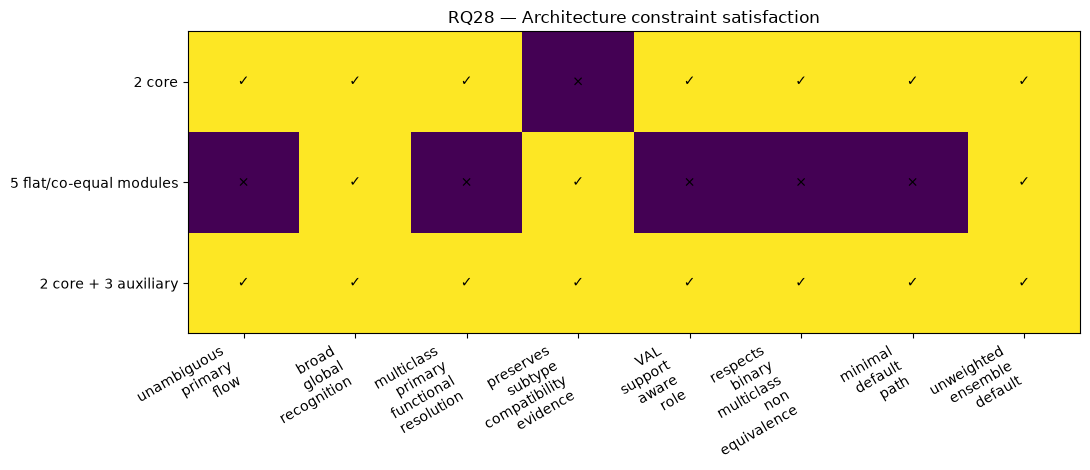

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_deployment/rq28/figures/rq28_architecture_constraint_matrix.png


In [12]:

# Figure 1 — mandatory constraint satisfaction.
matrix = architecture_comparison.set_index(
    "architecture_label"
)[CONSTRAINTS].astype(int)

fig, ax = plt.subplots(figsize=(11.0, 4.8))
im = ax.imshow(matrix.to_numpy(), aspect="auto", vmin=0, vmax=1)

ax.set_xticks(
    np.arange(len(CONSTRAINTS)),
    [c.replace("_", "\n") for c in CONSTRAINTS],
    rotation=30,
    ha="right",
)
ax.set_yticks(
    np.arange(len(matrix)),
    matrix.index,
)

for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        ax.text(
            j, i,
            "✓" if matrix.iloc[i, j] else "×",
            ha="center",
            va="center",
        )

ax.set_title("RQ28 — Architecture constraint satisfaction")
fig.tight_layout()

path = FIG_DIR / "rq28_architecture_constraint_matrix.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


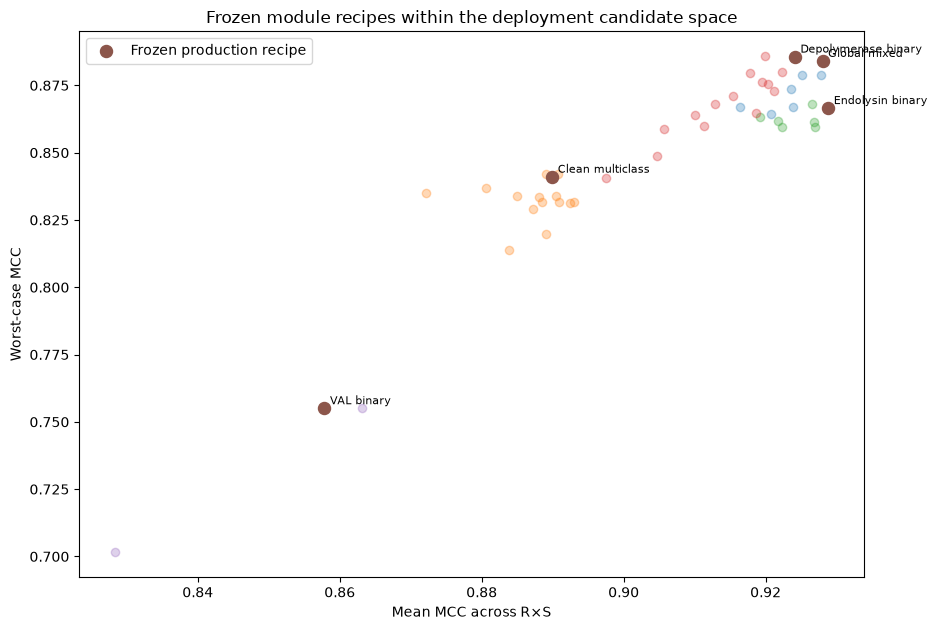

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_deployment/rq28/figures/rq28_frozen_recipes_mean_vs_worst.png


In [13]:

# Figure 2 — selected production recipe in mean/worst space.
fig, ax = plt.subplots(figsize=(9.5, 6.4))

for task in PRODUCTION_ENDPOINTS:
    g = candidate_options[
        candidate_options["task"].eq(task)
    ]
    ax.scatter(
        g["mean_mcc"],
        g["worst_mcc"],
        alpha=0.30,
        label=None,
    )

selected = selected_recipes.copy()
ax.scatter(
    selected["mean_mcc"],
    selected["worst_mcc"],
    s=75,
    label="Frozen production recipe",
)

for row in selected.itertuples(index=False):
    ax.annotate(
        TASK_LABEL[row.task],
        (row.mean_mcc, row.worst_mcc),
        xytext=(4, 3),
        textcoords="offset points",
        fontsize=8,
    )

ax.set_xlabel("Mean MCC across R×S")
ax.set_ylabel("Worst-case MCC")
ax.set_title("Frozen module recipes within the deployment candidate space")
ax.legend()
fig.tight_layout()

path = FIG_DIR / "rq28_frozen_recipes_mean_vs_worst.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)


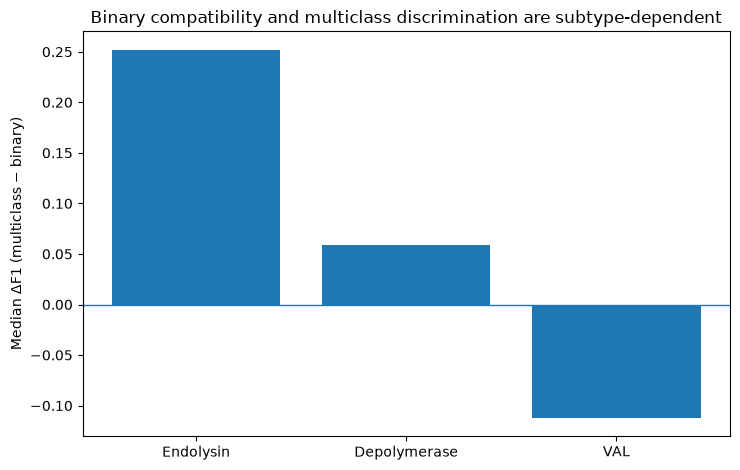

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_deployment/rq28/figures/rq28_RQ11_formulation_shift.png


In [14]:

# Figure 3 — RQ11 formulation shift supporting auxiliary semantics.
plot = rq11_architecture_evidence.copy()
plot = plot.set_index("subtype").reindex(
    ["endolysin", "depolymerase", "val"]
)

if "delta_f1_median" in plot.columns:
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    ax.bar(
        ["Endolysin", "Depolymerase", "VAL"],
        plot["delta_f1_median"].to_numpy(),
    )
    ax.axhline(0, linewidth=1)
    ax.set_ylabel("Median ΔF1 (multiclass − binary)")
    ax.set_title(
        "Binary compatibility and multiclass discrimination are subtype-dependent"
    )
    fig.tight_layout()

    path = FIG_DIR / "rq28_RQ11_formulation_shift.png"
    fig.savefig(path, dpi=220, bbox_inches="tight")
    plt.show()
    print("Saved:", path)


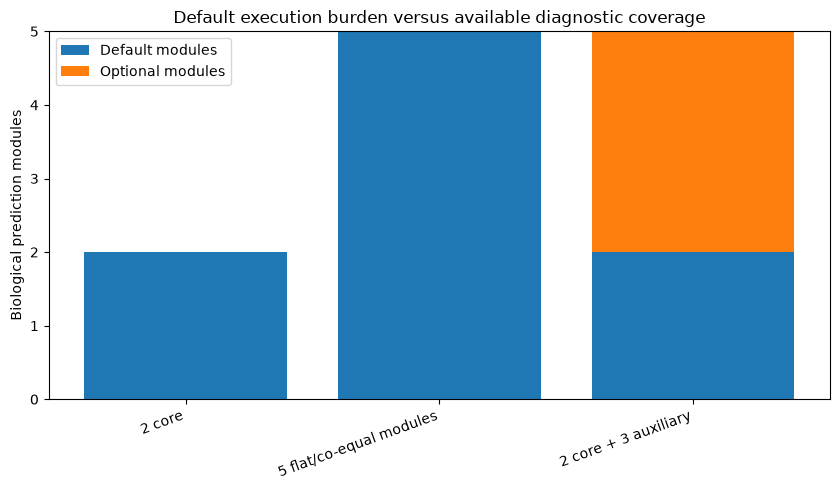

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_deployment/rq28/figures/rq28_architecture_module_burden.png


In [15]:

# Figure 4 — default versus optional module burden.
plot = architecture_comparison.set_index("architecture_label")

x = np.arange(len(plot))
fig, ax = plt.subplots(figsize=(8.5, 5.0))
ax.bar(
    x,
    plot["default_modules"],
    label="Default modules",
)
ax.bar(
    x,
    plot["total_available_modules"] - plot["default_modules"],
    bottom=plot["default_modules"],
    label="Optional modules",
)
ax.set_xticks(x, plot.index, rotation=20, ha="right")
ax.set_ylabel("Biological prediction modules")
ax.set_title("Default execution burden versus available diagnostic coverage")
ax.legend()
fig.tight_layout()

path = FIG_DIR / "rq28_architecture_module_burden.png"
fig.savefig(path, dpi=220, bbox_inches="tight")
plt.show()
print("Saved:", path)



## 13. Interpretation guardrails

RQ28 freezes the product architecture, but several distinctions remain essential.

### Architecture is not a new performance benchmark

The three architectures cannot be compared by simply averaging MCC across their modules. They expose different outputs and answer different biological questions. The architecture choice is therefore constraint-based.

### Global hard is not the production global classifier

Its higher apparent separability reflects a distinct lysis-adjacent comparison universe. It remains scientifically useful as a benchmark stress-test but does not define broad global recognition.

### Auxiliary binaries do not override multiclass

Binary positive predictions mean subtype compatibility relative to non-lytic background. Multiclass is the primary clean functional discrimination layer.

A disagreement can be surfaced as a diagnostic, not resolved by majority vote across semantically different tasks.

### VAL stays support-aware

VAL is retained as an auxiliary signal because its binary formulation contains information not captured reliably by clean multiclass discrimination. Its output must carry an evidence-limited warning.

### PU remains separate

Positive–unlabeled models serve discovery/ranking under unavailable true negatives. They are not inserted into the standard supervised PhageLysClass core.

### Recipe freeze is not fitted-weight freeze

RQ28 freezes tasks, representations, learners, ensemble membership, voting, and output hierarchy. Final all-data fitting and end-to-end inference validation belong to the production build/RQ29.


## 14. Export canonical RQ28 architecture artifacts

In [16]:

architecture_constraint_matrix = architecture_comparison[
    ["architecture_id", "architecture_label", *CONSTRAINTS]
].copy()

excluded_benchmark_tasks = global_task_roles[
    global_task_roles["production_status"].eq("evaluation_only")
].copy()

guardrails = pd.DataFrame([
    {
        "guardrail_id": "G1",
        "scope": "global",
        "rule": "Use global_mixed as production global formulation; easy/hard remain evaluation-only.",
    },
    {
        "guardrail_id": "G2",
        "scope": "functional",
        "rule": "Clean multiclass provides primary exclusive subtype assignment.",
    },
    {
        "guardrail_id": "G3",
        "scope": "auxiliary",
        "rule": "Binary subtype outputs are compatibility diagnostics and never override multiclass by voting.",
    },
    {
        "guardrail_id": "G4",
        "scope": "VAL",
        "rule": "VAL auxiliary output always carries an evidence-limited warning.",
    },
    {
        "guardrail_id": "G5",
        "scope": "ensemble",
        "rule": "Production ensembles use unweighted soft voting; no validation-weighted production recipe.",
    },
    {
        "guardrail_id": "G6",
        "scope": "training",
        "rule": "Do not promote a benchmark R/S outer-test cell to production training policy.",
    },
    {
        "guardrail_id": "G7",
        "scope": "PU",
        "rule": "PU discovery remains a separate workflow from standard supervised inference.",
    },
])

exports = {
    "rq28_preflight.tsv": preflight,
    "rq28_architecture_evidence_checks.tsv": architecture_evidence_checks,
    "rq28_global_definition_summary.tsv": global_definition_summary,
    "rq28_global_task_roles.tsv": global_task_roles,
    "rq28_RQ11_architecture_evidence.tsv": rq11_architecture_evidence,
    "rq28_candidate_recipes.tsv": candidate_options,
    "rq28_recipe_selection_audit.tsv": recipe_selection_audit,
    "rq28_selected_recipes.tsv": selected_recipes,
    "rq28_architecture_comparison.tsv": architecture_comparison,
    "rq28_architecture_constraint_matrix.tsv": architecture_constraint_matrix,
    "rq28_frozen_components.tsv": frozen_components,
    "rq28_architecture_complexity.tsv": architecture_complexity,
    "rq28_complexity_notes.tsv": complexity_notes,
    "rq28_RQ29_inference_contract.tsv": rq29_contract,
    "rq28_excluded_benchmark_tasks.tsv": excluded_benchmark_tasks,
    "rq28_guardrails.tsv": guardrails,
}

for filename, df in exports.items():
    path = RQ28_OUT / filename
    df.to_csv(path, sep="\t", index=False)
    print(f"Wrote {filename}: {len(df)} rows")

architecture_json = {
    "rq": "RQ28",
    "architecture_id": FROZEN_ARCHITECTURE_ID,
    "architecture_label": FROZEN_ARCHITECTURE_LABEL,
    "production_global_task": PRODUCTION_GLOBAL_TASK,
    "default_flow": [
        "core_global_lytic",
        "core_function_multiclass",
    ],
    "optional_auxiliary_outputs": [
        "aux_endolysin_compatibility",
        "aux_depolymerase_compatibility",
        "aux_VAL_compatibility",
    ],
    "components": frozen_components.to_dict("records"),
    "production_ensemble_policy": "unweighted_soft_only",
    "threshold_policy": (
        "No new threshold optimization in RQ28; benchmark operating points remain "
        "descriptive until production protocol is validated."
    ),
    "training_freeze_boundary": (
        "Freeze recipe only. Final fitted weights require all-data production retraining; "
        "benchmark R/S cells are not production split choices."
    ),
    "PU_policy": "separate_discovery_workflow",
    "next_stage": "RQ29 end-to-end inference validation",
}

with open(
    RQ28_OUT / "rq28_production_architecture.json",
    "w",
    encoding="utf-8",
) as fh:
    json.dump(architecture_json, fh, indent=2)

print("Wrote rq28_production_architecture.json")


Wrote rq28_preflight.tsv: 10 rows
Wrote rq28_architecture_evidence_checks.tsv: 4 rows
Wrote rq28_global_definition_summary.tsv: 3 rows
Wrote rq28_global_task_roles.tsv: 3 rows
Wrote rq28_RQ11_architecture_evidence.tsv: 3 rows
Wrote rq28_candidate_recipes.tsv: 47 rows
Wrote rq28_recipe_selection_audit.tsv: 43 rows
Wrote rq28_selected_recipes.tsv: 5 rows
Wrote rq28_architecture_comparison.tsv: 3 rows
Wrote rq28_architecture_constraint_matrix.tsv: 3 rows
Wrote rq28_frozen_components.tsv: 5 rows
Wrote rq28_architecture_complexity.tsv: 3 rows
Wrote rq28_complexity_notes.tsv: 4 rows
Wrote rq28_RQ29_inference_contract.tsv: 7 rows
Wrote rq28_excluded_benchmark_tasks.tsv: 2 rows
Wrote rq28_guardrails.tsv: 7 rows
Wrote rq28_production_architecture.json


## 15. Execution gates

In [17]:

required_exports = [
    *exports.keys(),
    "rq28_production_architecture.json",
]

assert len(master) == 2240
assert FORMULATION_DIRECTION_HETEROGENEOUS
assert VAL_MULTICLASS_PENALIZED
assert WEIGHTING_MATERIALLY_NEGLIGIBLE
assert VAL_ENSEMBLE_WEAKENS_STRICT
assert architecture_evidence_checks.loc[
    architecture_evidence_checks["required"], "value"
].all()

assert len(selected_recipes) == 5
assert selected_recipes["task"].nunique() == 5

assert FROZEN_ARCHITECTURE_ID == "C_2_core_plus_3_aux"
assert architecture_comparison[
    "all_mandatory_constraints"
].sum() == 1

assert len(frozen_components) == 5
assert frozen_components["tier"].eq("core").sum() == 2
assert frozen_components["tier"].eq("auxiliary").sum() == 3
assert frozen_components["default_execution"].sum() == 2

assert set(
    frozen_components.loc[
        frozen_components["tier"].eq("core"),
        "task",
    ]
) == {"global_mixed", "multiclass_clean"}

assert set(
    frozen_components.loc[
        frozen_components["tier"].eq("auxiliary"),
        "task",
    ]
) == {
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
}

assert (
    frozen_components.loc[
        frozen_components["task"].eq("subtype_val"),
        "option_type",
    ].iloc[0]
    == "single"
)

# No weighted ensemble may enter the frozen production recipe.
assert not frozen_components[
    "voting_scheme"
].eq("validation_weighted_soft").any()

# Easy/hard remain benchmark-only.
assert set(excluded_benchmark_tasks["task"]) == {
    "global_easy", "global_hard"
}

# Production recipe remains inside the established mean-competitive band.
assert selected_recipes[
    "mean_gap_to_task_best"
].le(COMPETITIVE_GAP + 1e-12).all()

assert all((RQ28_OUT / f).is_file() for f in required_exports)

figure_files = sorted(p.name for p in FIG_DIR.glob("*.png"))
assert len(figure_files) >= 4

print("RQ28_EXECUTION_GATES_OK")
print("Frozen architecture:", FROZEN_ARCHITECTURE_LABEL)
print("Core modules:", 2)
print("Auxiliary modules:", 3)
print("Default modules:", 2)
print("Frozen component recipes:", len(frozen_components))
print("Core fitted-estimator recipes:", frozen_core_estimators)
print("All fitted-estimator recipes if auxiliaries requested:", frozen_all_estimators)
print("Production global task:", PRODUCTION_GLOBAL_TASK)
print("Weighted production ensembles:", 0)
print("Exports:", len(required_exports))
print("Figures:", figure_files)
print()
print(
    "Interpretation status: execution gates passed. "
    "Assign REAL-DATA PASS only after the real executed notebook is inspected "
    "for errors, stderr, outputs, frozen recipes, and architecture coherence."
)


RQ28_EXECUTION_GATES_OK
Frozen architecture: 2 core + 3 auxiliary
Core modules: 2
Auxiliary modules: 3
Default modules: 2
Frozen component recipes: 5
Core fitted-estimator recipes: 4
All fitted-estimator recipes if auxiliaries requested: 10
Production global task: global_mixed
Weighted production ensembles: 0
Exports: 17
Figures: ['rq28_RQ11_formulation_shift.png', 'rq28_architecture_constraint_matrix.png', 'rq28_architecture_module_burden.png', 'rq28_frozen_recipes_mean_vs_worst.png']

Interpretation status: execution gates passed. Assign REAL-DATA PASS only after the real executed notebook is inspected for errors, stderr, outputs, frozen recipes, and architecture coherence.
